# EDA: Adult / Census Income

**Materia:** TC5061 Operaciones de aprendizaje automático  
**Alumno:** Carlos Eduardo Medina Flores

Este notebook se conserva **solo para la exploración de datos** (carga, descripción y EDA). La limpieza, el entrenamiento, la evaluación y el registro en MLflow se migraron al script `train.py` en la raíz del repositorio.

**Problema:** clasificación binaria. Con datos del censo de EE. UU. de 1994, predecir si una persona gana más de 50 mil dólares al año.

## 0. Configuración

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
RANDOM_STATE = 42

## 1. Carga y descripción del dataset

El dataset **Adult** (también llamado Census Income) viene del UCI Machine Learning Repository. El archivo `adult.data` no trae encabezados, así que los nombres de las columnas se asignan al leerlo. La primera vez se descarga desde UCI y se guarda una copia en `data/adult.csv` (en la raíz del repo, la misma que usa `train.py`); las siguientes corridas leen esa copia.

In [4]:
COLS = ["age", "workclass", "fnlwgt", "education", "education-num",
        "marital-status", "occupation", "relationship", "race", "sex",
        "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"]
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
LOCAL = Path("../data/adult.csv")

# Lee la copia local si existe; si no, descarga de UCI y la guarda
if LOCAL.exists():
    df_raw = pd.read_csv(LOCAL)
else:
    df_raw = pd.read_csv(URL, header=None, names=COLS)
    LOCAL.parent.mkdir(parents=True, exist_ok=True)
    df_raw.to_csv(LOCAL, index=False)

print("Registros y variables:", df_raw.shape)
df_raw.head()

Registros y variables: (32561, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [5]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


**Estructura:** el dataset tiene **32,561 registros** y **15 variables**: 6 numéricas (`int64`) y 9 de texto (`object`). Cada registro es una persona.

| Variable | Tipo | Significado |
|---|---|---|
| `age` | Numérica | Edad en años |
| `workclass` | Categórica | Tipo de empleador (privado, gobierno, autoempleo, etc.) |
| `fnlwgt` | Numérica | Peso muestral del censo: a cuántas personas de la población representa el registro |
| `education` | Categórica | Nivel máximo de estudios |
| `education-num` | Numérica | El mismo nivel de estudios, codificado como número ordinal (1 a 16) |
| `marital-status` | Categórica | Estado civil |
| `occupation` | Categórica | Ocupación |
| `relationship` | Categórica | Rol de la persona dentro de su hogar (esposo, hijo, sin familia, etc.) |
| `race` | Categórica | Raza |
| `sex` | Categórica | Sexo |
| `capital-gain` | Numérica | Ganancias de capital en el año (USD) |
| `capital-loss` | Numérica | Pérdidas de capital en el año (USD) |
| `hours-per-week` | Numérica | Horas trabajadas por semana |
| `native-country` | Categórica | País de origen |
| `income` | Categórica | **Variable objetivo:** ingreso anual `<=50K` o `>50K` |

## 2. Análisis exploratorio (EDA)

El EDA se hace sobre los datos tal como vienen, para que los problemas de calidad se vean antes de corregirlos en el Paso 3.

### 2.1 Estadísticas descriptivas

In [6]:
num_cols = df_raw.select_dtypes(include="number").columns.tolist()
cat_cols = df_raw.select_dtypes(exclude="number").columns.tolist()

df_raw[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.58,13.64,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.37,105549.98,12285.0,117827.0,178356.0,237051.0,1484705.0
education-num,32561.0,10.08,2.57,1.0,9.0,10.0,12.0,16.0
capital-gain,32561.0,1077.65,7385.29,0.0,0.0,0.0,0.0,99999.0
capital-loss,32561.0,87.30,402.96,0.0,0.0,0.0,0.0,4356.0
hours-per-week,32561.0,40.44,12.35,1.0,40.0,40.0,45.0,99.0


In [7]:
# Variables categóricas: número de categorías, la más frecuente y su frecuencia
df_raw[cat_cols].describe().T

,count,unique,top,freq
workclass,32561,9,Private,22696
education,32561,16,HS-grad,10501
marital-status,32561,7,Married-civ-spouse,14976
occupation,32561,15,Prof-specialty,4140
relationship,32561,6,Husband,13193
race,32561,5,White,27816
sex,32561,2,Male,21790
native-country,32561,42,United-States,29170
income,32561,2,<=50K,24720


**Hallazgos:**
- La edad va de 17 a 90 años, con media de 38.6 y mediana de 37.
- En `hours-per-week` el percentil 25 y la mediana son 40, así que la jornada de 40 horas domina; el rango va de 1 a 99.
- `capital-gain` y `capital-loss` valen 0 hasta el percentil 75, pero sus máximos son 99,999 y 4,356. Son variables muy sesgadas: casi todos tienen cero y unos pocos tienen valores muy altos.
- `fnlwgt` tiene una escala muy distinta al resto (de 12,285 a 1,484,705) porque no describe a la persona, sino al muestreo.
- En las categóricas hay categorías muy dominantes: `Private` en `workclass` (22,696 registros; 69.70%), `White` en `race` (85.43%), `Male` en `sex` (66.92%) y `United-States` en `native-country` (89.59%). `native-country` tiene 42 categorías, pero casi 9 de cada 10 registros caen en una sola.

### 2.2 Distribución de la variable objetivo

            n      %
income              
<=50K   24720  75.92
>50K     7841  24.08


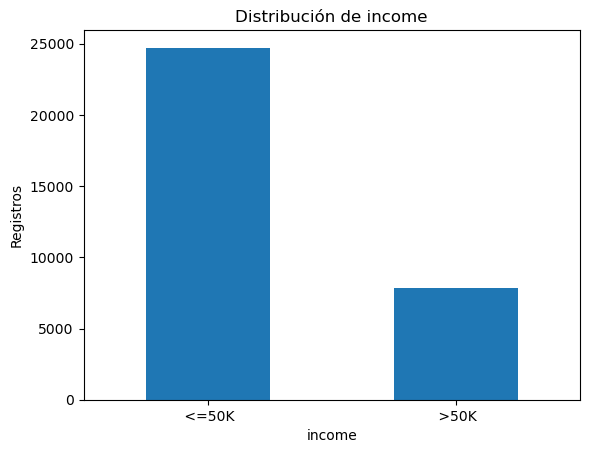

In [8]:
conteo = df_raw["income"].value_counts()
print(pd.DataFrame({"n": conteo, "%": (conteo / len(df_raw) * 100).round(2)}))

conteo.plot(kind="bar", rot=0, title="Distribución de income")
plt.ylabel("Registros")
plt.show()

**Hallazgo:** las clases están desbalanceadas: 24,720 personas (75.92%) ganan `<=50K` y 7,841 (24.08%) ganan `>50K`. Esto importa para la evaluación: un modelo que siempre prediga `<=50K` tendría cerca de 76% de accuracy sin aprender nada, así que el accuracy solo no basta.

### 2.3 Distribución de las variables numéricas

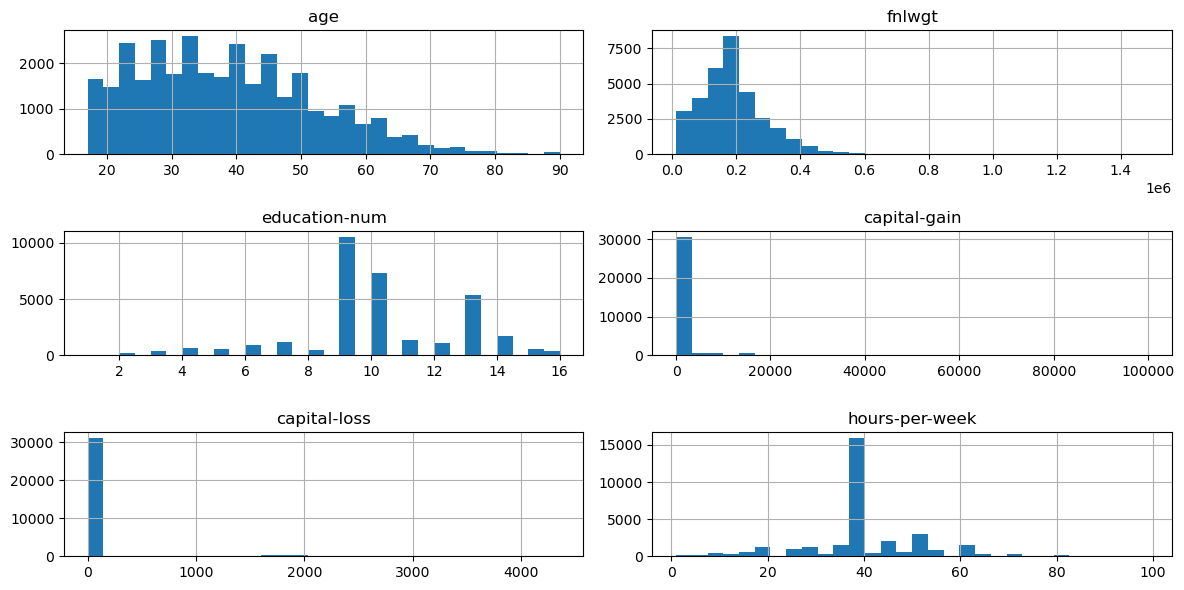

% de registros con valor 0:
capital-gain    91.67
capital-loss    95.33
dtype: float64

Sesgo (skewness):
age                0.56
fnlwgt             1.45
education-num     -0.31
capital-gain      11.95
capital-loss       4.59
hours-per-week     0.23
dtype: float64


In [9]:
df_raw[num_cols].hist(bins=30, figsize=(12, 6))
plt.tight_layout()
plt.show()

print("% de registros con valor 0:")
print((df_raw[["capital-gain", "capital-loss"]] == 0).mean().mul(100).round(2))
print("\nSesgo (skewness):")
print(df_raw[num_cols].skew().round(2))

**Hallazgos:**
- `capital-gain` y `capital-loss` valen 0 en el 91.67% y el 95.33% de los registros. Son las variables más sesgadas (skewness de 11.95 y 4.59).
- `age` (0.56), `education-num` (-0.31) y `hours-per-week` (0.23) tienen un sesgo bajo.
- `fnlwgt` tiene sesgo a la derecha (1.45).


### 2.4 Relación de las variables con el ingreso

education-num  education   
1              Preschool        0.0
2              1st-4th          3.6
3              5th-6th          4.8
4              7th-8th          6.2
5              9th              5.3
6              10th             6.6
7              11th             5.1
8              12th             7.6
9              HS-grad         16.0
10             Some-college    19.0
11             Assoc-voc       26.1
12             Assoc-acdm      24.8
13             Bachelors       41.5
14             Masters         55.7
15             Prof-school     73.4
16             Doctorate       74.1
Name: alto_ingreso, dtype: float64


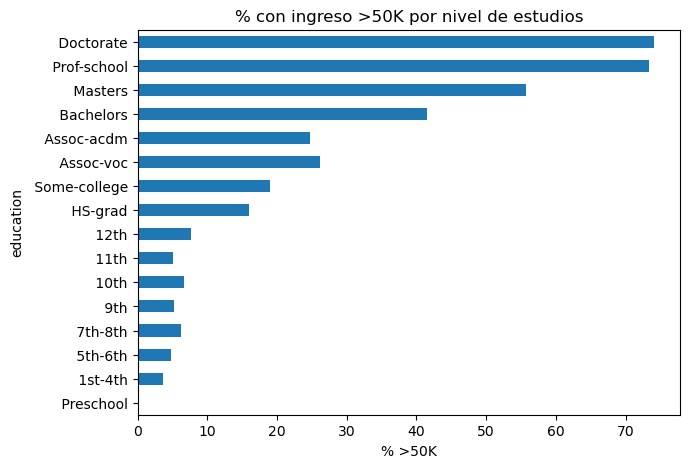

In [10]:
# Copia para el EDA con el objetivo en 0/1
eda = df_raw.copy()
eda["alto_ingreso"] = (eda["income"].str.strip() == ">50K").astype(int)

# % de personas con >50K por nivel de estudios, ordenado por education-num
tasa_edu = eda.groupby(["education-num", "education"])["alto_ingreso"].mean().mul(100).round(1)
print(tasa_edu)

tasa_edu.droplevel(0).plot(kind="barh", figsize=(7, 5), title="% con ingreso >50K por nivel de estudios")
plt.xlabel("% >50K")
plt.show()

sex
Female    10.9
Male      30.6
Name: alto_ingreso, dtype: float64 

marital-status
Never-married             4.6
Separated                 6.4
Married-spouse-absent     8.1
Widowed                   8.6
Divorced                 10.4
Married-AF-spouse        43.5
Married-civ-spouse       44.7
Name: alto_ingreso, dtype: float64 



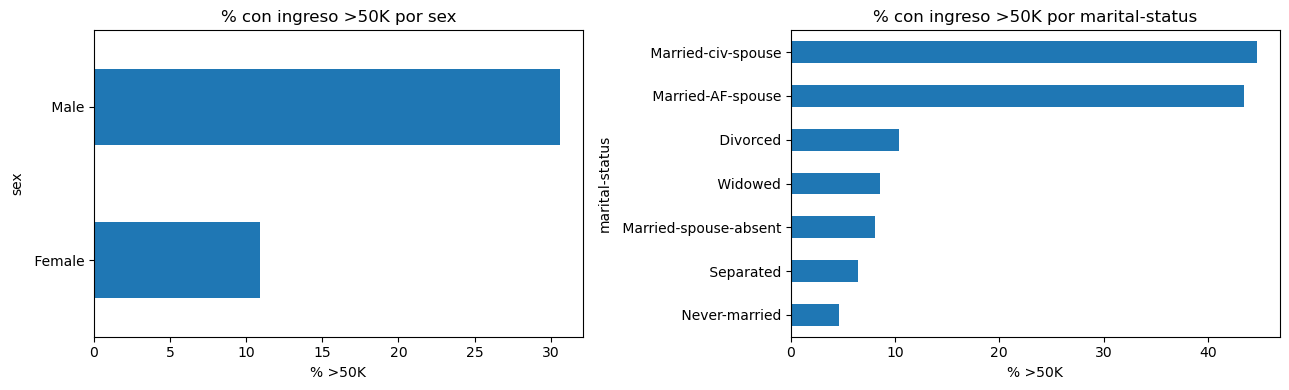

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["sex", "marital-status"]):
    tasa = eda.groupby(col)["alto_ingreso"].mean().mul(100).round(1).sort_values()
    print(tasa, "\n")
    tasa.plot(kind="barh", ax=ax, title=f"% con ingreso >50K por {col}")
    ax.set_xlabel("% >50K")
plt.tight_layout()
plt.show()

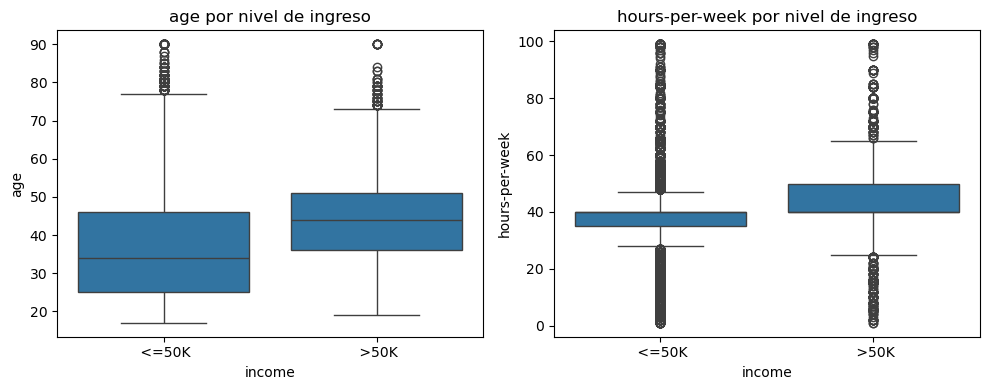

         age  hours-per-week
income                      
<=50K   34.0            40.0
>50K    44.0            40.0


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ["age", "hours-per-week"]):
    sns.boxplot(data=eda, x="income", y=col, ax=ax)
    ax.set_title(f"{col} por nivel de ingreso")
plt.tight_layout()
plt.show()

print(eda.groupby("income")[["age", "hours-per-week"]].median())

**Hallazgos:**
- **Estudios:** el porcentaje con ingreso `>50K` sube con el nivel de estudios. Es menor a 8% en quienes no terminaron la preparatoria, 16.0% con `HS-grad`, 41.5% con `Bachelors`, 55.7% con `Masters` y más de 73% con `Prof-school` y `Doctorate`.
- **Sexo:** 30.6% de los hombres gana `>50K`, contra 10.9% de las mujeres.
- **Estado civil:** 44.7% en `Married-civ-spouse`, contra 4.6% en `Never-married` y entre 6.4% y 10.4% en separados, viudos y divorciados.
- **Edad:** la mediana es de 44 años en el grupo `>50K` y de 34 en el grupo `<=50K`.
- **Horas:** la mediana es de 40 horas en los dos grupos, así que la mediana por sí sola no los distingue.

Son asociaciones, no causas. Además, `sex` y `race` son variables sensibles: un modelo que las use puede reproducir desigualdades que ya existen en los datos.

### 2.5 Correlación entre variables numéricas

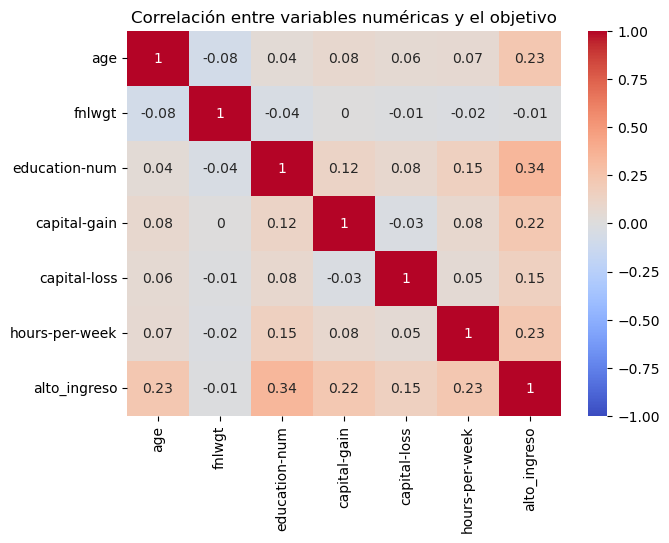

alto_ingreso      1.00
education-num     0.34
age               0.23
hours-per-week    0.23
capital-gain      0.22
capital-loss      0.15
fnlwgt           -0.01
Name: alto_ingreso, dtype: float64


In [13]:
corr = eda[num_cols + ["alto_ingreso"]].corr().round(2)
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables numéricas y el objetivo")
plt.show()

print(corr["alto_ingreso"].sort_values(ascending=False))

**Hallazgos:** ninguna variable numérica tiene una correlación fuerte con el objetivo. La más alta es `education-num` (0.34), seguida de `age` (0.23), `hours-per-week` (0.23), `capital-gain` (0.22) y `capital-loss` (0.15). `fnlwgt` no tiene relación con el ingreso (-0.01), lo que apoya eliminarla en la limpieza.